# Domestic Flight Price Prediction
Regression on `price` with linear and tree-based models. Each model is trained and scored with the same 5-fold cross-validation. The linear models are a point of comparison; the final prediction comes from the tree-based models only: the average of the six strongest tree models, corrected with an exact-match lookup for flights that already appear in the training data.

**Linear models** (compared with the trees, not used in the final blend)
1. Linear Regression (baseline)
2. Ridge (L2 penalty)
3. Lasso (L1 penalty)
4. Ridge with airline-specific duration slopes

**Tree-based models**

5. Decision Tree (baseline)
6. Random Forest: log target and raw price
7. XGBoost: log target and Gamma objective
8. LightGBM: Tweedie objective and log target

**Contents:** 1. Setup · 2. Exploratory data analysis · 3. Preprocessing and feature engineering · 4. Design choices tested · 5. Cross-validation framework · 6. Models · 7. Log vs raw target · 8. Results · 9. Final blend · 10. Exact-match lookup · 11. Error analysis · 12. Submission · 13. Conclusion


## 1. Setup and data

In [1]:
import os, time, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
import xgboost as xgb
import lightgbm as lgb
warnings.filterwarnings("ignore")

SEED = 42
kf = KFold(5, shuffle=True, random_state=SEED)   # the same 5 folds for every model, the blend and the lookup

DATA_DIR = next((d for d in ["", "/content/", "data/"] if os.path.exists(d + "train.csv")), "")
train = pd.read_csv(DATA_DIR + "train.csv")
test = pd.read_csv(DATA_DIR + "test.csv")
sample = pd.read_csv(DATA_DIR + "sample_submission.csv")

# Data integrity check: a row missing any of these columns is unusable (airline and duration may be missing).
core = ["flight", "source_city", "departure_time", "stops", "arrival_time", "destination_city",
        "flight_class", "days_left", "price"]
bad = train[core].isna().any(axis=1)
if bad.any():
    print(f"Dropping {int(bad.sum())} incomplete training row(s), ids: {train.loc[bad, 'id'].tolist()[:10]}")
    train = train.loc[~bad].reset_index(drop=True)
train = train.astype({"days_left": "int64", "price": "int64"})
print(train.shape, test.shape, sample.shape)
train.head()

(15589, 12) (3898, 11) (3898, 2)


,id,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,flight_class,duration,days_left,price
0,1,Wayfarer Aviation,IX 1070,Metropolis,Evening,zero,Night,Springfield,Economy,NaN,18,8909
1,2,Oceanic Airlines,6E 285,Los Santos,Night,zero,Night,Springfield,Economy,1.33,38,5115
2,3,Wayfarer Aviation,AI 2641,Night City,Evening,zero,Night,Springfield,Business,2.08,13,35247
3,4,Oceanic Airlines,6E 6704,Night City,Afternoon,zero,Evening,Metropolis,Economy,2.25,5,6457
4,5,Oceanic Airlines,6E 234,Hill Valley,Evening,one,Night,Springfield,Economy,4.83,21,6842


## 2. Exploratory data analysis

In [2]:
print("Missing values (train):"); print(train.isna().sum()[lambda s: s > 0])
print("\nMissing values (test):"); print(test.isna().sum()[lambda s: s > 0])
print("\nDuplicate feature rows in train:", train.drop(columns=["id", "price"]).duplicated().sum())
train.describe().T

Missing values (train):
airline     3089
duration    3095
dtype: int64

Missing values (test):
airline     799
duration    776
dtype: int64

Duplicate feature rows in train: 314


,count,mean,std,min,25%,50%,75%,max
id,15589.0,7795.000000,4500.301008,1.00,3898.00,7795.0,11692.00,15589.00
duration,12494.0,4.300499,4.181832,0.92,2.25,2.5,4.92,38.08
days_left,15589.0,22.461928,13.036812,1.00,12.00,22.0,33.00,57.00
price,15589.0,29816.695555,39127.890925,3801.00,7210.00,10183.0,35968.00,323177.00


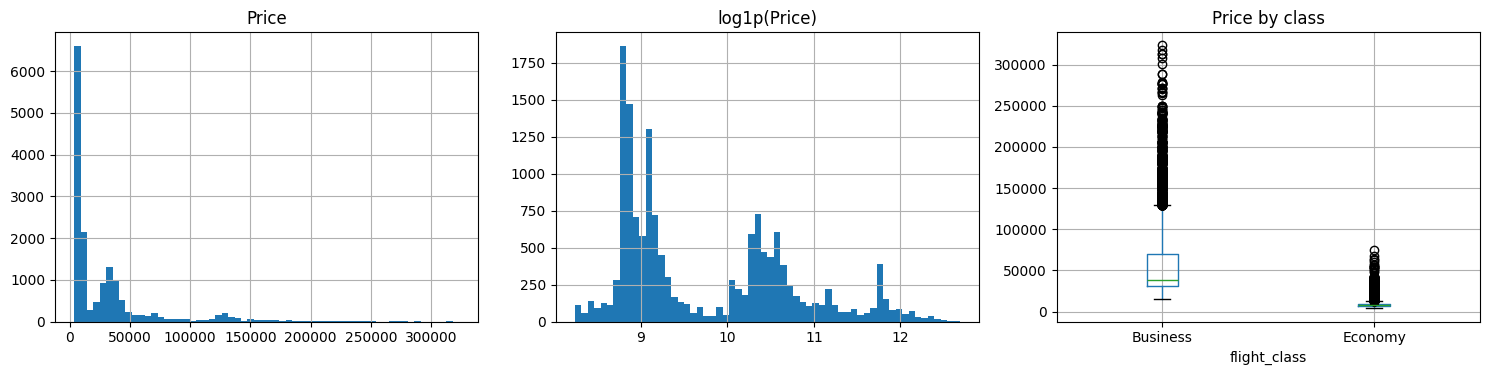

flight_class
Business    60127.0
Economy      8818.0
stops
one             62782.0
two_or_more    130463.0
zero            15508.0


In [3]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
train.price.hist(bins=60, ax=ax[0]); ax[0].set_title("Price")
np.log1p(train.price).hist(bins=60, ax=ax[1]); ax[1].set_title("log1p(Price)")
train.boxplot(column="price", by="flight_class", ax=ax[2]); ax[2].set_title("Price by class"); plt.suptitle("")
plt.tight_layout(); plt.show()
print(train.groupby("flight_class").price.mean().round(0).to_string())
print(train.groupby("stops").price.mean().round(0).to_string())

**How price moves with booking time, departure time and airline.** Mean price by days before departure, by departure time and by airline, shown separately for each class because the two classes differ by roughly 7x.

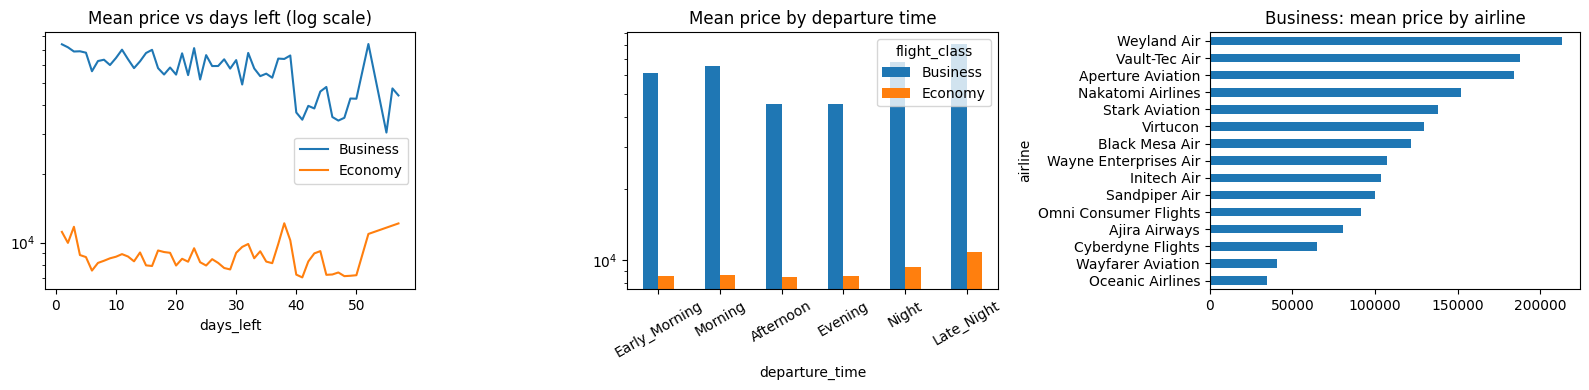

Business : booking within 7 days costs 1.14x the average of later bookings
Economy  : booking within 7 days costs 1.08x the average of later bookings


In [4]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for c, g in train.groupby("flight_class"):
    g.groupby("days_left").price.mean().plot(ax=ax[0], label=c)
ax[0].set_yscale("log"); ax[0].set_title("Mean price vs days left (log scale)"); ax[0].set_xlabel("days_left"); ax[0].legend()

order = ["Early_Morning", "Morning", "Afternoon", "Evening", "Night", "Late_Night"]
(train.pivot_table(index="departure_time", columns="flight_class", values="price", aggfunc="mean")
      .reindex(order).plot.bar(ax=ax[1], logy=True, rot=30, title="Mean price by departure time"))

bz = train[train.flight_class == "Business"]
bz.groupby("airline").price.mean().sort_values().plot.barh(ax=ax[2], title="Business: mean price by airline")
plt.tight_layout(); plt.show()

late, early = train[train.days_left <= 7], train[train.days_left > 7]
for c in ["Business", "Economy"]:
    r = late[late.flight_class == c].price.mean() / early[early.flight_class == c].price.mean()
    print(f"{c:9s}: booking within 7 days costs {r:.2f}x the average of later bookings")

In [5]:
# Finding 1: the flight-code prefix determines the airline (one-to-one)
allf = pd.concat([train.drop(columns="price"), test], ignore_index=True)
allf["prefix"] = allf.flight.str.split().str[0]
n_air = allf.dropna(subset=["airline"]).groupby("prefix").airline.nunique()
print("Prefixes mapping to more than one airline:", int((n_air > 1).sum()), "of", len(n_air))
# Finding 2: missing duration is mostly recoverable from the same flight + route + stops
key = ["flight", "source_city", "destination_city", "stops"]
known = allf.dropna(subset=["duration"]).groupby(key).duration.median().rename("k").reset_index()
miss = allf[allf.duration.isna()].merge(known, on=key, how="left")
print("Missing durations recoverable from flight+route+stops: %.1f%%" % (100 * miss.k.notna().mean()))
# Finding 3: the two classes have very different price levels and spreads
for c, g in train.groupby("flight_class"):
    print(f"{c:9s} rows {len(g):6d} | mean price {g.price.mean():9.0f} | std {g.price.std():9.0f}")

Prefixes mapping to more than one airline: 0 of 20
Missing durations recoverable from flight+route+stops: 97.8%
Business  rows   6380 | mean price     60127 | std     46415
Economy   rows   9209 | mean price      8818 | std      4670


**Category counts, unseen flights and price spread within a flight.** How many rows each category has (rare airlines and the `two_or_more` stops level have very few rows, so anything learned about them is noisy), how many test rows have a flight code that never appears in train, and how much the price of the same flight varies within a class.

In [6]:
# Rows per category (airline counts include missing values, which are filled later from the flight-code prefix)
for col in ["airline", "source_city", "destination_city", "departure_time", "arrival_time", "stops", "flight_class"]:
    vc = train[col].value_counts(dropna=False)
    print(f"{col} ({vc.size} levels): " + ", ".join(f"{k} {v}" for k, v in vc.items()))

airline (19 levels): Wayfarer Aviation 5200, Oceanic Airlines 5112, nan 3089, Sandpiper Air 697, Stark Aviation 336, Ajira Airways 330, Nakatomi Airlines 319, Wayne Enterprises Air 180, Vandelay Aviation 115, Virtucon 85, Vault-Tec Air 48, Aperture Aviation 25, Omni Consumer Flights 24, Initech Air 9, Weyland Air 8, Black Mesa Air 6, Massive Dynamic 2, Hooli Airways 2, Cyberdyne Flights 2
source_city (6 levels): Metropolis 6198, Night City 2651, Springfield 2051, Hill Valley 1600, Gotham 1586, Los Santos 1503
destination_city (6 levels): Night City 4663, Springfield 2870, Metropolis 2759, Hill Valley 2126, Los Santos 1609, Gotham 1562
departure_time (6 levels): Evening 3304, Morning 3296, Night 2832, Early_Morning 2680, Afternoon 2462, Late_Night 1015
arrival_time (6 levels): Night 3845, Morning 3116, Evening 2968, Afternoon 2860, Late_Night 1826, Early_Morning 974
stops (3 levels): zero 10965, one 4558, two_or_more 66
flight_class (2 levels): Economy 9209, Business 6380


In [7]:
# Flight codes in test that never appear in train: for these rows a model can only use airline, route and the other columns
seen_flights = set(train.flight)
print(f"Distinct flight codes: train {train.flight.nunique()}, test {test.flight.nunique()}")
print(f"Test rows with a flight code not seen in train: {(~test.flight.isin(seen_flights)).mean():.1%}")

# Price spread within one flight code and class (flights with at least 5 rows), measured as std / mean
spread = train.groupby(["flight_class", "flight"]).price.agg(["count", "mean", "std"])
spread = spread[spread["count"] >= 5]
spread_cv = (spread["std"] / spread["mean"]).rename("std / mean")
print("\nWithin-flight price spread (std / mean) by class:")
display(spread_cv.groupby(level="flight_class").describe()[["count", "25%", "50%", "75%", "max"]].round(3))

Distinct flight codes: train 1070, test 872
Test rows with a flight code not seen in train: 0.9%

Within-flight price spread (std / mean) by class:


,count,25%,50%,75%,max
flight_class,,,,,
Business,345.0,0.088,0.161,0.262,0.650
Economy,641.0,0.071,0.150,0.256,0.943


## 3. Preprocessing and feature engineering
- **airline**: filled from the flight-code prefix (the mapping is exact), plus a missing flag.
- **duration**: hierarchical median imputation (flight+route+stops, then airline+route+stops, then route+stops, then stops, then global), plus a missing flag. It uses features only, never the target, so there is no leakage.
- **Ordinal encodings** for stops and time of day; **combinations** route, route×class and airline×class.
- **Derived features**: flight number, duration per leg, days-left buckets, last-minute flag (≤ 7 days), how often each flight appears.
- **Categoricals**: airline, flight prefix, cities, route, route×class, airline×class, departure and arrival time, class and stops.

In [8]:
TIME_ORDER = {"Early_Morning": 0, "Morning": 1, "Afternoon": 2, "Evening": 3, "Night": 4, "Late_Night": 5}
STOPS_ORDER = {"zero": 0, "one": 1, "two_or_more": 2}

def build_features(tr, te):
    n_tr = len(tr)
    al = pd.concat([tr.drop(columns="price"), te], ignore_index=True)

    parts = al["flight"].str.split(" ", n=1, expand=True)
    al["flight_prefix"] = parts[0]
    al["flight_num"] = pd.to_numeric(parts[1], errors="coerce")

    pref2air = al.dropna(subset=["airline"]).groupby("flight_prefix")["airline"].agg(lambda s: s.mode().iat[0])
    al["airline_missing"] = al["airline"].isna().astype(int)
    al["airline"] = al["airline"].fillna(al["flight_prefix"].map(pref2air)).fillna("Unknown")

    al["duration_missing"] = al["duration"].isna().astype(int)
    al["route"] = al["source_city"] + "_" + al["destination_city"]
    dur = al["duration"].copy()
    for k in (["flight", "route", "stops"], ["airline", "route", "stops"], ["route", "stops"], ["stops"]):
        dur = dur.fillna(al.groupby(k)["duration"].transform("median"))
    al["duration"] = dur.fillna(al["duration"].median())

    al["stops_n"] = al["stops"].map(STOPS_ORDER)
    al["dep_n"] = al["departure_time"].map(TIME_ORDER)
    al["arr_n"] = al["arrival_time"].map(TIME_ORDER)
    al["is_business"] = (al["flight_class"] == "Business").astype(int)
    al["dur_per_stop"] = al["duration"] / (al["stops_n"] + 1)
    al["days_bucket"] = (pd.cut(al["days_left"], bins=[-np.inf, 2, 7, 14, 21, 35, np.inf], labels=False)
                         .fillna(-1).astype(int))
    al["last_minute"] = (al["days_left"] <= 7).astype(int)
    al["flight_count"] = al.groupby("flight")["flight"].transform("count")
    al["route_class"] = al["route"] + "_" + al["flight_class"]
    al["airline_class"] = al["airline"] + "_" + al["flight_class"]

    cat_cols = ["airline", "flight_prefix", "source_city", "destination_city", "route", "route_class",
                "airline_class", "departure_time", "arrival_time", "flight_class", "stops"]
    num_cols = ["flight_num", "duration", "dur_per_stop", "days_left", "days_bucket", "last_minute", "stops_n",
                "dep_n", "arr_n", "is_business", "airline_missing", "duration_missing", "flight_count"]
    X = al[cat_cols + num_cols].copy()
    for c in cat_cols:
        X[c] = X[c].astype("category")
    return X.iloc[:n_tr].reset_index(drop=True), tr["price"].values, X.iloc[n_tr:].reset_index(drop=True), cat_cols

Xc, y, Xtc, cats = build_features(train, test)
print("features:", Xc.shape[1], "| NaNs left:", int(Xc.isna().sum().sum() + Xtc.isna().sum().sum()))
Xc.head()

features: 24 | NaNs left: 0


,airline,flight_prefix,source_city,destination_city,route,route_class,airline_class,departure_time,arrival_time,flight_class,...,days_left,days_bucket,last_minute,stops_n,dep_n,arr_n,is_business,airline_missing,duration_missing,flight_count
0,Wayfarer Aviation,IX,Metropolis,Springfield,Metropolis_Springfield,Metropolis_Springfield_Economy,Wayfarer Aviation_Economy,Evening,Night,Economy,...,18,3,0,0,3,4,0,0,1,24
1,Oceanic Airlines,6E,Los Santos,Springfield,Los Santos_Springfield,Los Santos_Springfield_Economy,Oceanic Airlines_Economy,Night,Night,Economy,...,38,5,0,0,4,4,0,0,0,12
2,Wayfarer Aviation,AI,Night City,Springfield,Night City_Springfield,Night City_Springfield_Business,Wayfarer Aviation_Business,Evening,Night,Business,...,13,2,0,0,3,4,1,0,0,37
3,Oceanic Airlines,6E,Night City,Metropolis,Night City_Metropolis,Night City_Metropolis_Economy,Oceanic Airlines_Economy,Afternoon,Evening,Economy,...,5,1,1,0,2,3,0,0,0,15
4,Oceanic Airlines,6E,Hill Valley,Springfield,Hill Valley_Springfield,Hill Valley_Springfield_Economy,Oceanic Airlines_Economy,Evening,Night,Economy,...,21,3,0,1,3,4,0,0,0,16


### One-hot pipeline for the scikit-learn models
The Decision Tree and Random Forest need numeric inputs, so `wrap_sklearn_tree(estimator)` one-hot encodes the categorical columns and passes the numeric ones through. The encoder is fitted **inside each CV fold** (and inside each class for per-class models) on the training rows only; `handle_unknown="ignore"` gives all-zeros for categories first seen in the validation fold, so nothing leaks. XGBoost and LightGBM handle categoricals natively and do not use it.

In [9]:
def wrap_sklearn_tree(estimator):
    try:
        ohe = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    except TypeError:                                  # older scikit-learn
        ohe = OneHotEncoder(handle_unknown="ignore", sparse=False)
    prep = ColumnTransformer([("ohe", ohe, cats)], remainder="passthrough")
    return Pipeline([("prep", prep), ("model", estimator)])

width = wrap_sklearn_tree(DecisionTreeRegressor()).named_steps["prep"].fit(Xc).transform(Xc.head(3)).shape[1]
print("columns after one-hot:", width, "(from", Xc.shape[1], ")")

columns after one-hot: 197 (from 24 )


### Inputs and pipeline for the linear models
The linear models use the same features as the trees (`Xc` and `Xtc` above, which are not modified), with two differences that apply **only to the linear models**:
- **Added:** the full flight code (e.g. "EY 353") as a one-hot feature. For a linear model it is the strongest single feature (R² 0.796 → 0.896 in the earlier linear experiments, section 4). The trees leave it out because it made XGBoost worse.
- **Dropped:** `flight_num`. A flight number is a label, not a quantity, so a linear model would wrongly read flight 6704 as "30x flight 234". Trees only split on it, so they keep it.

`wrap_linear(estimator)` turns these features into numbers a linear model can use. Like `wrap_sklearn_tree`, it is fitted **inside each CV fold** (and inside each class) on the training rows only:
- categorical columns → one-hot (`handle_unknown="ignore"`, so categories first seen in the validation fold get all-zeros)
- `duration` and `days_left` → cubic **splines** (6 knots), then standardised, so the model can bend the price curve along these two features instead of fitting a straight line
- other numeric columns → standardised
- optional (`slopes=True`): one duration column per airline with at least 30 training rows (section 6.4)

In [10]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.preprocessing import StandardScaler, SplineTransformer
from sklearn.linear_model import LinearRegression, Ridge, Lasso

# Copies of Xc / Xtc for the linear models only: flight code added, flight_num dropped
Xl = Xc.drop(columns=["flight_num"]).assign(flight=train["flight"].astype(str).values)
Xtl = Xtc.drop(columns=["flight_num"]).assign(flight=test["flight"].fillna("Unknown").astype(str).values)
LIN_CATS = cats + ["flight"]
LIN_SPLINE = ["duration", "days_left"]
LIN_NUM = [col for col in Xl.columns if col not in LIN_CATS + LIN_SPLINE]

class AirlineDurationSlopes(BaseEstimator, TransformerMixin):
    """One column per airline with >= min_n training rows: duration / 10 on that airline's rows, 0 elsewhere."""
    def __init__(self, min_n=30):
        self.min_n = min_n
    def fit(self, X, y=None):
        counts = X["airline"].astype(str).value_counts()
        self.airlines_ = counts[counts >= self.min_n].index.tolist()
        return self
    def transform(self, X):
        air, dur = X["airline"].astype(str).to_numpy(), X["duration"].to_numpy(float) / 10
        return np.column_stack([np.where(air == a, dur, 0.0) for a in self.airlines_] or [np.zeros(len(X))])

def wrap_linear(estimator, slopes=False):
    blocks = [("ohe", OneHotEncoder(handle_unknown="ignore"), LIN_CATS),
              ("spline", Pipeline([("s", SplineTransformer(n_knots=6, degree=3)), ("sc", StandardScaler())]), LIN_SPLINE),
              ("num", StandardScaler(), LIN_NUM)]
    if slopes:
        blocks.append(("slopes", AirlineDurationSlopes(min_n=30), ["airline", "duration"]))
    return Pipeline([("prep", ColumnTransformer(blocks)), ("model", estimator)])

lin_width = wrap_linear(LinearRegression()).named_steps["prep"].fit(Xl).transform(Xl.head(3)).shape[1]
print("linear-model features:", Xl.shape[1], "| columns after one-hot and splines:", lin_width)

linear-model features: 24 | columns after one-hot and splines: 1280


## 4. Design choices tested during development
Every choice below was compared on the same 5-fold cross-validation, and the better option was kept. RMSE is in rupees (lower is better).

**Features**

| Choice | Result | Kept |
|---|---|---|
| `stops` as a categorical feature, no separate log-duration feature | mean RMSE of LightGBM and XGBoost 10,408.6 → 10,376.3 | yes |
| Full flight identifier (e.g. "EY 353", ~1,070 levels) as an extra categorical | XGBoost 7% worse; LightGBM 0.7% better, but still behind the final LightGBM set-up below | no |
| Target-encoded neighbour features (average price of similar flights) | R² dropped to 0.921 | no |

**Separate models for Business and Economy (per-class) vs one model for both (pooled)**

Business fares are about 7x higher and much noisier than Economy, so fitting each class on its own lets the trees spend their splits within a class instead of separating the two.

| Model | Pooled RMSE | Per-class RMSE | Kept |
|---|---|---|---|
| Decision Tree (log) | 11,797 | 12,008 | pooled |
| Random Forest (log) | 10,255 | 10,275 | pooled |
| Random Forest (raw) | 10,399 | 10,389 | per-class |
| XGBoost (log) | 10,128 | 10,268 | pooled |
| XGBoost (Gamma) | 10,217 | 10,214 | per-class |
| LightGBM (Tweedie) | 10,263 | 10,175 | per-class |
| LightGBM (log) | 10,259 | 10,235 | per-class |

**Tree size for the boosting models.** Deeper trees vs shallower, more regularised trees (best RMSE of each):

| Model | Deeper trees | Shallower trees | Kept |
|---|---|---|---|
| XGBoost (log) | 10,394 (depth 7, L2 = 2) | 10,128 (depth 5, L2 = 5) | shallower |
| XGBoost (Gamma) | 10,410 (depth 7, L2 = 2) | 10,214 (depth 5, L2 = 5) | shallower |
| LightGBM (log) | 10,359 (63 leaves) | 10,235 (15 leaves) | shallower |
| LightGBM (Tweedie) | 10,350 (63 leaves) | 10,175 (7 leaves) | shallower |

**Combining models.** Averaging several models consistently beat the best single model (R² 0.9330 for the best single model vs 0.9346-0.9359 for averages of 4 to 19 models), and multiplying the average by 1.01 to undo the downward bias of log-target models lowered RMSE every time. Both are checked again in section 9 on the final models, and the exact-match lookup weight is chosen in section 10.

Section 7 compares log, raw, Tweedie and Gamma targets on the final models.

**Linear models (earlier experiments).** These choices come from the earlier linear-model notebook, which used its own simpler preprocessing and was scored on an 80/20 hold-out split (hold-out R²) or with 5-fold CV on the 80% (CV R²). They fix the set-up used in sections 6.1-6.4; the penalty strengths are re-tuned in section 6 on the current features.

| Choice | Result | Kept |
|---|---|---|
| Full flight code as a one-hot feature (Ridge) | hold-out R² 0.7959 → 0.8959 | yes |
| Separate models for Business and Economy | hold-out R² 0.8993 → 0.9167 | yes |
| Splines on `duration` and `days_left` | hold-out R² 0.9167 → 0.9170 | yes |
| Log target | hold-out R² 0.9170 → 0.9207 | yes |
| One duration slope per airline | CV R² 0.9149 → 0.9192 | yes (section 6.4) |
| The same slopes without capping predictions to the training range | some folds diverged (CV R² far below 0) | no, predictions are capped |
| Polynomial interactions of the numeric features | hold-out R² 0.8959 → 0.8959 | no |
| Extra crosses (days left as a category, airline × days bucket, airline × stops, route × stops, departure × arrival) | CV R² changed by −0.0011 to +0.0009 | no |
| Per-class scale-up to undo the log-target bias | hold-out R² 0.9207 → 0.9197 | no |
| Lasso and ElasticNet instead of Ridge | CV R² 0.9118 and 0.9134 vs 0.9149 | Ridge stronger; Lasso kept for comparison |

## 5. Cross-validation framework
`cv_fit` trains a model on 4 folds and predicts the 5th, five times, so every training row gets an **out-of-fold (OOF)** prediction from a model that never saw it. The test prediction is the average of the five fold models. All predictions are stored on the **raw price scale** (log-target models are converted back with `expm1`), so every model is scored the same way and can be averaged.

- `target="log"` trains on log1p(price); `target="raw"` trains on the price itself (section 7 explains the difference).
- `per_class=True` fits two models inside each fold, one on Business rows and one on Economy rows; each predicts only its own class.

In [11]:
OOF, TEST, ROWS = {}, {}, []
CLASSES = ["Business", "Economy"]
CLS = train["flight_class"].astype(str).values
CLS_T = test["flight_class"].astype(str).values
assert set(CLS) <= set(CLASSES) and set(CLS_T) <= set(CLASSES)

def metrics(y_true, p):
    return dict(RMSE=np.sqrt(mean_squared_error(y_true, p)), MAE=mean_absolute_error(y_true, p),
                R2=r2_score(y_true, p),
                RMSLE=np.sqrt(mean_squared_error(np.log1p(y_true), np.log1p(np.clip(p, 1, None)))))

def cv_fit(key, builder, target="log", per_class=False):
    """5-fold CV: stores out-of-fold and fold-averaged test predictions (raw price scale) under `key`."""
    t0 = time.time()
    oof, tp = np.zeros(len(y)), np.zeros(len(Xtc))
    if per_class:
        groups = [(CLS == c, CLS_T == c) for c in CLASSES]
    else:
        groups = [(np.ones(len(y), bool), np.ones(len(Xtc), bool))]
    for a, b in kf.split(Xc):
        for in_tr, in_te in groups:
            ia, ib, it = a[in_tr[a]], b[in_tr[b]], np.where(in_te)[0]
            m = builder()
            m.fit(Xc.iloc[ia], np.log1p(y[ia]) if target == "log" else y[ia])
            pb, pt = m.predict(Xc.iloc[ib]), m.predict(Xtc.iloc[it])
            if target == "log":
                pb, pt = np.expm1(pb), np.expm1(pt)
            oof[ib] = pb; tp[it] += pt / kf.n_splits
    OOF[key], TEST[key] = oof, tp
    r = metrics(y, oof)
    r.update(model=key, training="per-class" if per_class else "pooled", secs=round(time.time() - t0, 1))
    ROWS[:] = [x for x in ROWS if x["model"] != key] + [r]
    print(f"{key:18s} RMSE {r['RMSE']:9.1f} | MAE {r['MAE']:7.1f} | R2 {r['R2']:.4f} | {r['secs']}s")

### Cross-validation for the linear models
`cv_fit_linear` is the linear-model version of `cv_fit`: the same 5 folds, out-of-fold and fold-averaged test predictions on the raw price scale, and the same metrics. All four linear models use a log target and separate Business and Economy models (section 4), so these are fixed rather than options. Two differences:
- Predictions are capped, in log space, to the training fold's price range ± about 10% before converting back. A linear model can extrapolate to absurd prices for rare combinations; a tree cannot.
- Results go to their own store (`LIN_OOF`, `LIN_TEST`, `LIN_ROWS`), so the tree results, blend and submission in sections 7-12 are exactly the same as without the linear models.

`tune_fit_linear` tries several penalty strengths (α) on the same folds, prints each score and keeps the one with the lowest CV RMSE.

In [12]:
LIN_OOF, LIN_TEST, LIN_ROWS = {}, {}, []

def _cv_linear(builder):
    """5-fold CV, log target, one model per class; returns out-of-fold and fold-averaged test predictions (raw price)."""
    oof, tp = np.zeros(len(y)), np.zeros(len(Xtl))
    groups = [(CLS == c, CLS_T == c) for c in CLASSES]
    for a, b in kf.split(Xl):
        for in_tr, in_te in groups:
            ia, ib, it = a[in_tr[a]], b[in_tr[b]], np.where(in_te)[0]
            ylog = np.log1p(y[ia])
            lo, hi = ylog.min() - 0.1, ylog.max() + 0.1           # cap to the training range +- ~10%
            m = builder()
            m.fit(Xl.iloc[ia], ylog)
            oof[ib] = np.expm1(np.clip(m.predict(Xl.iloc[ib]), lo, hi))
            tp[it] += np.expm1(np.clip(m.predict(Xtl.iloc[it]), lo, hi)) / kf.n_splits
    return oof, tp

def _store_linear(key, oof, tp, secs):
    LIN_OOF[key], LIN_TEST[key] = oof, tp
    r = metrics(y, oof)
    r.update(model=key, training="per-class", secs=secs)
    LIN_ROWS[:] = [x for x in LIN_ROWS if x["model"] != key] + [r]
    print(f"{key:20s} RMSE {r['RMSE']:9.1f} | MAE {r['MAE']:7.1f} | R2 {r['R2']:.4f} | {r['secs']}s")

def cv_fit_linear(key, builder):
    t0 = time.time()
    oof, tp = _cv_linear(builder)
    _store_linear(key, oof, tp, round(time.time() - t0, 1))

def tune_fit_linear(key, make, alphas):
    """Scores make(alpha) for each alpha on the same folds; stores and returns the alpha with the lowest CV RMSE."""
    best = None
    for alpha in alphas:
        t0 = time.time()
        oof, tp = _cv_linear(lambda: make(alpha))
        secs, rmse = round(time.time() - t0, 1), metrics(y, oof)["RMSE"]
        print(f"  alpha={alpha:<8g} RMSE {rmse:9.1f} | {secs}s")
        if best is None or rmse < best[1]:
            best = (alpha, rmse, oof, tp, secs)
    print(f"  -> alpha={best[0]:g}")
    _store_linear(key, best[2], best[3], best[4])
    return best[0]

## 6. Models
Sections 6.1-6.4 are the linear models and 6.5-6.11 the tree-based models.

### 6.1 Linear Regression (baseline)
**What we do:** ordinary least squares: find the coefficients that minimise squared error on log(price), with no penalty on their size. Inputs come from `wrap_linear` (one-hot categoricals including the flight code, splines on duration and days left, scaled numeric columns), with separate models for Business and Economy.

**Why:** it is the simplest model, so it is the linear baseline. With more than a thousand one-hot columns, many of them flights seen only a few times, an unpenalised fit memorises noise in rare categories; comparing it with Ridge and Lasso shows how much regularisation helps.

In [13]:
cv_fit_linear("LinearRegression", lambda: wrap_linear(LinearRegression()))

LinearRegression     RMSE   11262.4 | MAE  4125.8 | R2 0.9171 | 8.8s


### 6.2 Ridge (L2 penalty)
**What we do:** the same linear model plus an L2 penalty α·Σβ² that shrinks every coefficient towards zero. α is chosen from 0.03, 0.1, 0.3, 1 and 3 by CV RMSE.

**Why:** the penalty stops rare flights and airlines from getting extreme coefficients, while common categories with plenty of rows barely move. Ridge was the strongest plain linear model in the earlier experiments (section 4).

In [14]:
RIDGE_ALPHA = tune_fit_linear("Ridge", lambda a: wrap_linear(Ridge(alpha=a, solver="lsqr")), [0.03, 0.1, 0.3, 1, 3])

  alpha=0.03     RMSE   11256.9 | 1.9s
  alpha=0.1      RMSE   11244.9 | 1.9s
  alpha=0.3      RMSE   11234.2 | 1.7s
  alpha=1        RMSE   11252.0 | 1.6s
  alpha=3        RMSE   11351.7 | 1.4s
  -> alpha=0.3
Ridge                RMSE   11234.2 | MAE  4089.8 | R2 0.9176 | 1.7s


### 6.3 Lasso (L1 penalty)
**What we do:** an L1 penalty α·Σ|β| instead of L2, with α = 3e-5. A CV search over 3e-5, 1e-4, 3e-4 and 1e-3 gave RMSE 11,256, 11,369, 11,683 and 12,487, so the smallest value was kept; the search is not repeated here because Lasso is slow. The L1 penalty sets many coefficients exactly to zero, so Lasso also selects features; the cell prints how many it keeps.

**Why:** a different kind of regularisation from Ridge: it drops the columns it finds useless instead of shrinking all of them a little. It is the slowest linear model, because it is fitted coordinate by coordinate over many sparse columns.

In [15]:
LASSO_ALPHA = 3e-5   # chosen by CV: 3e-5 -> 11,256 | 1e-4 -> 11,369 | 3e-4 -> 11,683 | 1e-3 -> 12,487
lasso = lambda a: wrap_linear(Lasso(alpha=a, max_iter=5000, selection="random", random_state=SEED))
cv_fit_linear("Lasso", lambda: lasso(LASSO_ALPHA))

# How many coefficients does Lasso keep? (one fit per class on all training rows, for illustration only)
for cls_name in CLASSES:
    rows_c = CLS == cls_name
    coef = lasso(LASSO_ALPHA).fit(Xl.loc[rows_c], np.log1p(y[rows_c])).named_steps["model"].coef_
    print(f"{cls_name:9s}: Lasso keeps {int(np.sum(coef != 0))} of {coef.size} coefficients")

Lasso                RMSE   11256.2 | MAE  4102.4 | R2 0.9172 | 513.8s
Business : Lasso keeps 520 of 699 coefficients
Economy  : Lasso keeps 645 of 1150 coefficients


### 6.4 Ridge with airline-specific duration slopes
**What we do:** Ridge with extra columns: for every airline with at least 30 training rows in the class, `duration / 10` on that airline's rows and 0 elsewhere. α is chosen from 0.1, 0.3, 1 and 3 by CV RMSE.

**Why:** in the plain models every airline shares one duration curve, so a longer flight adds the same percentage to the fare on every airline. Premium airlines charge much more for long, one-stop Business itineraries, which is where most of the error sits (section 11). Giving each airline its own slope was the best linear variant in the earlier experiments (CV R² 0.9149 → 0.9192, section 4).

In [16]:
SLOPES_ALPHA = tune_fit_linear("Ridge_airline_slopes", lambda a: wrap_linear(Ridge(alpha=a, solver="lsqr"), slopes=True),
                               [0.1, 0.3, 1, 3])

  alpha=0.1      RMSE   11027.7 | 1.9s
  alpha=0.3      RMSE   11018.4 | 1.8s
  alpha=1        RMSE   11031.1 | 1.7s
  alpha=3        RMSE   11138.6 | 1.5s
  -> alpha=0.3
Ridge_airline_slopes RMSE   11018.4 | MAE  4039.0 | R2 0.9207 | 1.8s


### 6.5 Decision Tree (baseline)
**What we do:** fit a single regression tree on log(price), one model for both classes. The tree repeatedly splits the data on the feature and threshold that most reduce squared error, and predicts the average of each leaf.

**Why:** it is the simplest tree model and easy to interpret, so it is the baseline the other models must beat. A single tree has high variance, so depth is capped at 14 and every leaf needs at least 3 rows. It is not used in the final blend.

In [17]:
cv_fit("DecisionTree_log",
       lambda: wrap_sklearn_tree(DecisionTreeRegressor(max_depth=14, min_samples_leaf=3, random_state=SEED)),
       target="log")

DecisionTree_log   RMSE   11797.2 | MAE  3782.2 | R2 0.9091 | 1.2s


### 6.6 Random Forest (log target)
**What we do:** train 500 deep trees, each on a bootstrap sample of the rows and considering a random 80% of the (one-hot) columns at each split, and average their predictions. The target is log(price), and one forest covers both classes (this beat separate per-class forests, section 4).

**Why:** averaging many decorrelated trees removes most of a single tree's variance. Leaves need at least 2 rows to avoid memorising single noisy fares.

In [18]:
rf = lambda: wrap_sklearn_tree(RandomForestRegressor(n_estimators=500, max_features=0.8, min_samples_leaf=2,
                                                     n_jobs=-1, random_state=SEED))
cv_fit("RandomForest_log", rf, target="log")

RandomForest_log   RMSE   10256.3 | MAE  3208.8 | R2 0.9313 | 180.5s


### 6.7 Random Forest (raw price)
**What we do:** the same forest, but trained on the price in rupees instead of log(price), with **separate forests for Business and Economy** (per-class was slightly better here, section 4).

**Why:** a raw-price model predicts the mean fare directly, which is what RMSE rewards, while the log model predicts a slightly lower, median-like fare. Their errors differ, which makes the pair more useful in the blend than either alone.

In [19]:
cv_fit("RandomForest_raw", rf, target="raw", per_class=True)

RandomForest_raw   RMSE   10388.7 | MAE  3321.2 | R2 0.9295 | 168.5s


### 6.8 XGBoost (log target)
**What we do:** gradient boosting: 1,000 trees built one after another, each correcting the errors of the ones before it, with a small learning rate (0.03). Trees are shallow (depth 5) with an L2 penalty of 5 on leaf values, and each tree sees 80% of the rows and 70% of the columns. Categoricals are handled natively (no one-hot). The target is log(price), one model for both classes.

**Why:** boosting is usually the strongest model on tabular data. The shallow, regularised trees were clearly better than deeper ones on these noisy fares (section 4). This is the best single model.

In [20]:
xgb_model = lambda n_trees, **kw: xgb.XGBRegressor(n_estimators=n_trees, learning_rate=0.03, max_depth=5, subsample=0.8,
                                                   colsample_bytree=0.7, min_child_weight=2, reg_lambda=5.0,
                                                   tree_method="hist", enable_categorical=True, n_jobs=-1,
                                                   random_state=SEED, **kw)
cv_fit("XGBoost_log", lambda: xgb_model(1000), target="log")

XGBoost_log        RMSE   10127.0 | MAE  3273.2 | R2 0.9330 | 14.3s


### 6.9 XGBoost (Gamma objective)
**What we do:** the same shallow XGBoost (800 trees) trained on the raw price with the **Gamma** objective, with **separate models for Business and Economy**.

**Why:** the Gamma objective models price with a log link: like the log target it treats errors as relative, which suits skewed, always-positive prices, but it still predicts the mean fare in rupees, so it does not have the log target's downward bias.

In [21]:
cv_fit("XGBoost_gamma", lambda: xgb_model(800, objective="reg:gamma"), target="raw", per_class=True)

XGBoost_gamma      RMSE   10214.9 | MAE  3276.5 | R2 0.9318 | 14.7s


### 6.10 LightGBM (Tweedie objective)
**What we do:** LightGBM grows trees leaf by leaf (always splitting the leaf that most reduces error) on binned features, with native categorical splits. 1,500 trees at learning rate 0.03, each with only **7 leaves**, at least 5 rows per leaf, 80% row and 70% column sampling. Trained on the raw price with the **Tweedie** objective, with **separate models for Business and Economy**.

**Why:** Tweedie, like Gamma, uses a log link and predicts the mean fare. Very small trees plus per-class models worked best for this objective (section 4); it is the second-best single model.

In [22]:
lgb_model = lambda leaves, **kw: lgb.LGBMRegressor(n_estimators=1500, learning_rate=0.03, num_leaves=leaves,
                                                   subsample=0.8, subsample_freq=1, colsample_bytree=0.7,
                                                   min_child_samples=5, reg_lambda=2.0, cat_smooth=20, n_jobs=-1,
                                                   random_state=SEED, verbose=-1, **kw)
cv_fit("LightGBM_tweedie", lambda: lgb_model(7, objective="tweedie", tweedie_variance_power=1.5),
       target="raw", per_class=True)

LightGBM_tweedie   RMSE   10174.3 | MAE  3494.0 | R2 0.9324 | 12.9s


### 6.11 LightGBM (log target)
**What we do:** the same LightGBM set-up with **15 leaves** per tree, trained on log(price), with **separate models for Business and Economy**.

**Why:** a log-target counterpart to the Tweedie model: the same algorithm with a different loss makes different mistakes, which helps the blend.

In [23]:
cv_fit("LightGBM_log", lambda: lgb_model(15), target="log", per_class=True)

LightGBM_log       RMSE   10234.5 | MAE  3275.0 | R2 0.9316 | 15.5s


## 7. Log vs raw vs Tweedie / Gamma target
**Raw target.** The model minimises squared error in rupees. A few very expensive Business fares dominate that loss, so trees chase their noise. Its predictions estimate the *mean* price, which is what RMSE rewards.

**Log target.** The model fits log1p(price), so errors become percentages: a 10% miss counts the same on an ₹8k Economy fare and a ₹200k Business fare. This tames skew and noise. The catch: `expm1(prediction)` estimates a *median-like* price, slightly below the mean when noise is multiplicative. The scale factor printed below measures that bias; it is why the final blend is multiplied by 1.01 (section 9).

**Tweedie / Gamma objective.** Models the raw price with a log link: relative errors like the log target, but it still estimates the mean in rupees. It is the compromise between the two.

In [24]:
# Bias check: how far below the true mean is a log-target model? (1.00 = unbiased)
o = OOF["XGBoost_log"]
for c in CLASSES:
    m = CLS == c
    print(f"{c:9s} best scale factor for XGBoost_log: {np.sum(y[m] * o[m]) / np.sum(o[m] ** 2):.3f}")
print()
for fam, a, b in [("RandomForest", "log", "raw"), ("XGBoost", "log", "gamma"), ("LightGBM", "log", "tweedie")]:
    ra = metrics(y, OOF[f"{fam}_{a}"])["RMSE"]; rb = metrics(y, OOF[f"{fam}_{b}"])["RMSE"]
    print(f"{fam:13s} RMSE {a}: {ra:8.1f}   {b}: {rb:8.1f}   -> {a if ra < rb else b} is better")

Business  best scale factor for XGBoost_log: 1.016
Economy   best scale factor for XGBoost_log: 1.018

RandomForest  RMSE log:  10256.3   raw:  10388.7   -> log is better
XGBoost       RMSE log:  10127.0   gamma:  10214.9   -> log is better
LightGBM      RMSE log:  10234.5   tweedie:  10174.3   -> tweedie is better


## 8. Results
Cross-validated scores of every tree-based model (out-of-fold predictions on all training rows), then the same table with the linear models added.

,training,RMSE,MAE,R2,RMSLE,secs
model,,,,,,
XGBoost_log,pooled,10127.0053,3273.1913,0.9330,0.1305,14.3
LightGBM_tweedie,per-class,10174.2752,3494.0080,0.9324,0.1367,12.9
XGBoost_gamma,per-class,10214.9049,3276.5042,0.9318,0.1293,14.7
LightGBM_log,per-class,10234.5152,3274.9526,0.9316,0.1288,15.5
RandomForest_log,pooled,10256.2841,3208.7645,0.9313,0.1332,180.5
RandomForest_raw,per-class,10388.7102,3321.2250,0.9295,0.1367,168.5
DecisionTree_log,pooled,11797.2318,3782.2148,0.9091,0.1597,1.2


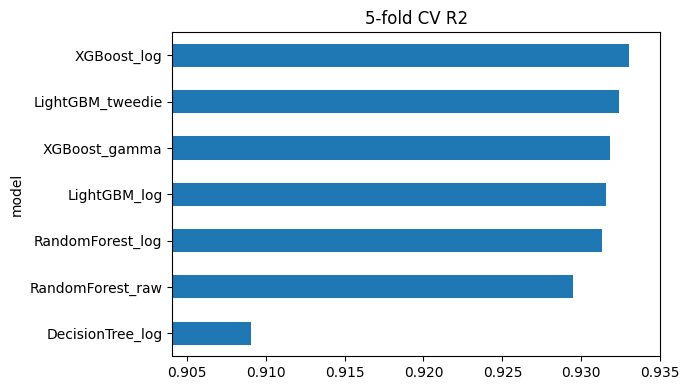

In [25]:
res = pd.DataFrame(ROWS).set_index("model")[["training", "RMSE", "MAE", "R2", "RMSLE", "secs"]].sort_values("RMSE")
display(res.round(4))
ax = res["R2"].sort_values().plot.barh(figsize=(7, 4), xlim=(res.R2.min() - 0.005, res.R2.max() + 0.002),
                                       title="5-fold CV R2")
plt.tight_layout(); plt.show()

**Linear vs tree-based models.** The same scores with the four linear models added (same folds, same metrics). The linear models are not used in the blend below.

,family,training,RMSE,MAE,R2,RMSLE,secs
model,,,,,,,
XGBoost_log,tree,pooled,10127.0053,3273.1913,0.9330,0.1305,14.3
LightGBM_tweedie,tree,per-class,10174.2752,3494.0080,0.9324,0.1367,12.9
XGBoost_gamma,tree,per-class,10214.9049,3276.5042,0.9318,0.1293,14.7
LightGBM_log,tree,per-class,10234.5152,3274.9526,0.9316,0.1288,15.5
RandomForest_log,tree,pooled,10256.2841,3208.7645,0.9313,0.1332,180.5
RandomForest_raw,tree,per-class,10388.7102,3321.2250,0.9295,0.1367,168.5
Ridge_airline_slopes,linear,per-class,11018.4455,4038.9564,0.9207,0.1737,1.8
Ridge,linear,per-class,11234.2026,4089.8035,0.9176,0.1744,1.7
Lasso,linear,per-class,11256.1734,4102.3975,0.9172,0.1738,513.8


Best linear: Ridge_airline_slopes (RMSE 11018.4, R2 0.9207) | best tree: XGBoost_log (RMSE 10127.0, R2 0.9330)


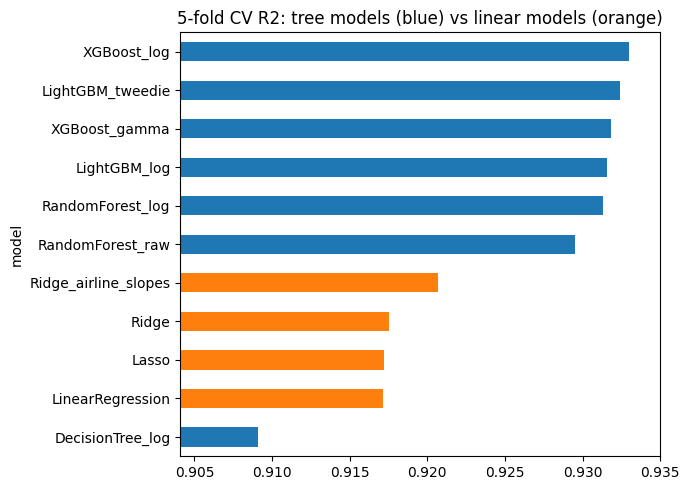

In [26]:
lin_res = pd.DataFrame(LIN_ROWS).set_index("model")[["training", "RMSE", "MAE", "R2", "RMSLE", "secs"]]
compare = pd.concat([lin_res.assign(family="linear"), res.assign(family="tree")]).sort_values("RMSE")
display(compare[["family", "training", "RMSE", "MAE", "R2", "RMSLE", "secs"]].round(4))
best_lin, best_tree = lin_res.RMSE.idxmin(), res.drop(index="DecisionTree_log").RMSE.idxmin()
print(f"Best linear: {best_lin} (RMSE {lin_res.loc[best_lin, 'RMSE']:.1f}, R2 {lin_res.loc[best_lin, 'R2']:.4f}) | "
      f"best tree: {best_tree} (RMSE {res.loc[best_tree, 'RMSE']:.1f}, R2 {res.loc[best_tree, 'R2']:.4f})")
by_r2 = compare.sort_values("R2")
colors = ["tab:blue" if f == "tree" else "tab:orange" for f in by_r2["family"]]
by_r2["R2"].plot.barh(figsize=(7, 5), color=colors, xlim=(by_r2.R2.min() - 0.005, by_r2.R2.max() + 0.002),
                      title="5-fold CV R2: tree models (blue) vs linear models (orange)")
plt.tight_layout(); plt.show()

## 9. Final blend
The six models other than the Decision Tree are averaged with equal weights. No weights are fitted, so the blend cannot overfit the validation folds. The cell compares the best single model with the plain average and the average × 1.01 (the log-target bias correction), and keeps whichever has the lowest CV RMSE.

In [27]:
BLEND_MODELS = ["RandomForest_log", "RandomForest_raw", "XGBoost_log", "XGBoost_gamma",
                "LightGBM_tweedie", "LightGBM_log"]
avg_oof = np.mean([OOF[k] for k in BLEND_MODELS], axis=0)
avg_test = np.mean([TEST[k] for k in BLEND_MODELS], axis=0)
best_single = res.drop(index="DecisionTree_log").index[0]

options = {
    f"best single model ({best_single})": (OOF[best_single], TEST[best_single]),
    "average of 6 models": (avg_oof, avg_test),
    "average of 6 models x 1.01": (avg_oof * 1.01, avg_test * 1.01),
}
blend_table = pd.DataFrame({k: metrics(y, v[0]) for k, v in options.items()}).T.sort_values("RMSE")
display(blend_table.round(4))
choice = blend_table.index[0]
base_cv, base_test = options[choice]
print("Used for the submission:", choice)

,RMSE,MAE,R2,RMSLE
average of 6 models x 1.01,9990.3394,3299.1751,0.9348,0.1287
average of 6 models,10005.5384,3224.1441,0.9346,0.1280
best single model (XGBoost_log),10127.0053,3273.1913,0.9330,0.1305


Used for the submission: average of 6 models x 1.01


## 10. Exact-match lookup
About 8% of test rows have an **exact twin** in train: same flight, route, class, days left, departure and arrival time, and stops. Most such twin groups share an identical price, so the twin's price is a much better guess than any model's. The final prediction for those rows mixes the twin's mean price with the blend; the weight is chosen by CV from the sweep below.

The evaluation is fold-safe: in each CV fold the lookup table is built **only from the training folds**, so a row never sees its own price.

In [28]:
tkey = ["flight", "source_city", "destination_city", "flight_class", "days_left",
        "departure_time", "arrival_time", "stops"]

twin_cv = np.full(len(train), np.nan)
for tr_idx, va_idx in kf.split(Xc):
    fold_lookup = train.iloc[tr_idx].groupby(tkey)["price"].mean()
    twin_cv[va_idx] = fold_lookup.reindex(pd.MultiIndex.from_frame(train.iloc[va_idx][tkey])).to_numpy()
has_twin = np.isfinite(twin_cv)

def with_twin(base, twin, wt):
    out = base.copy(); h = np.isfinite(twin)
    out[h] = wt * twin[h] + (1 - wt) * base[h]
    return out

sweep = pd.DataFrame({wt: metrics(y, with_twin(base_cv, twin_cv, wt))
                      for wt in (0.0, 0.5, 0.6, 0.7, 0.75, 0.8, 0.85, 0.9, 1.0)}).T.rename_axis("twin weight")
display(sweep[["RMSE", "MAE", "R2"]].round(4))
W_TWIN = float(sweep["RMSE"].idxmin())
print(f"train rows with a twin (fold-safe): {100 * has_twin.mean():.1f}% | chosen twin weight: {W_TWIN}")

final_cv = with_twin(base_cv, twin_cv, W_TWIN)
fm = metrics(y, final_cv)
print("FINAL (CV): RMSE %.1f | MAE %.1f | R2 %.4f" % (fm["RMSE"], fm["MAE"], fm["R2"]))

# apply to test using all training rows as the lookup table
tw_tab = train.groupby(tkey)["price"].mean().rename("twin").reset_index()
tw_test = test.merge(tw_tab, on=tkey, how="left")["twin"].values
test_final = with_twin(base_test, tw_test, W_TWIN)
print("test rows with a twin: %.1f%%" % (100 * np.isfinite(tw_test).mean()))

,RMSE,MAE,R2
twin weight,,,
0.00,9990.3394,3299.1751,0.9348
0.50,9899.7873,3222.4283,0.9360
0.60,9889.9827,3208.1564,0.9361
0.70,9882.9715,3194.0984,0.9362
0.75,9880.5152,3187.2309,0.9362
0.80,9878.7594,3180.4748,0.9363
0.85,9877.7043,3173.8851,0.9363
0.90,9877.3501,3167.3850,0.9363
1.00,9878.7449,3154.4655,0.9363


train rows with a twin (fold-safe): 7.1% | chosen twin weight: 0.9
FINAL (CV): RMSE 9877.4 | MAE 3167.4 | R2 0.9363
test rows with a twin: 8.3%


## 11. Error analysis: where is the remaining error?
This section checks whether the remaining error sits in Business tickets, particular airlines or particular price ranges, and so whether more feature engineering would be worth the time.

In [29]:
d = train.assign(pred=final_cv, se=(final_cv - y) ** 2, ae=np.abs(final_cv - y))
tot = d.se.sum()

print("1) Share of squared error by class")
print((d.groupby("flight_class").se.sum() / tot).round(3).to_string())

print("\n2) Business: RMSE and error share by airline")
bz = d[d.flight_class == "Business"]
air = bz.groupby("airline").agg(rows=("se", "size"), rmse=("se", lambda s: np.sqrt(s.mean())), sse_share=("se", lambda s: s.sum() / tot))
display(air.sort_values("sse_share", ascending=False).head(8).round(3))

print("3) Business: by number of stops")
display(bz.groupby("stops").agg(rows=("se", "size"), rmse=("se", lambda s: np.sqrt(s.mean())), sse_share=("se", lambda s: s.sum() / tot)).round(3))

1) Share of squared error by class
flight_class
Business    0.985
Economy     0.015

2) Business: RMSE and error share by airline


,rows,rmse,sse_share
airline,,,
Nakatomi Airlines,282,48532.580,0.437
Stark Aviation,307,21675.235,0.095
Wayfarer Aviation,2496,6832.284,0.077
Ajira Airways,278,17125.015,0.054
Wayne Enterprises Air,168,14859.906,0.024
Virtucon,84,19576.084,0.021
Sandpiper Air,24,34912.296,0.019
Vault-Tec Air,48,24341.430,0.019


3) Business: by number of stops


,rows,rmse,sse_share
stops,,,
one,3495,19914.783,0.911
two_or_more,64,16852.668,0.012
zero,2821,5788.663,0.062


In [30]:
# 4) by price range (true price)
bins = [0, 8000, 15000, 40000, 100000, np.inf]
labels = ["<8k", "8-15k", "15-40k", "40-100k", ">100k"]
d["band"] = pd.cut(d.price, bins=bins, labels=labels)
d["ape"] = d.ae / d.price
gb_ = d.groupby("band", observed=False)
band = pd.DataFrame({"rows": gb_.size(), "rmse": gb_.se.mean() ** 0.5, "mape": gb_.ape.mean(),
                     "sse_share": gb_.se.sum() / tot})
band["row_share"] = band["rows"] / len(d)
display(band[["rows", "row_share", "rmse", "mape", "sse_share"]].round(3))

biz = d[d.flight_class == "Business"].se.sum() / tot
top3 = air.sort_values("sse_share", ascending=False).head(3)["sse_share"].sum()
hi = d[d.price > 100000].se.sum() / tot
top5 = d.se.nlargest(int(0.05 * len(d))).sum() / tot
print(f"Business tickets: {biz:.0%} of squared error | top-3 Business airlines: {top3:.0%} | tickets above 100k: {hi:.0%} | worst 5% of rows: {top5:.0%}")
if biz > 0.9 and hi > 0.5:
    print("-> The error is concentrated in a few very expensive Business fares. Generic feature work on cheap fares cannot move R2; "
          "only features that explain premium-airline pricing could, and the example below suggests that no such column exists.")
else:
    print("-> The error is spread across segments, so segment-specific feature engineering may still pay off.")

,rows,row_share,rmse,mape,sse_share
band,,,,,
<8k,4971,0.319,603.247,0.054,0.001
8-15k,3795,0.243,1154.096,0.071,0.003
15-40k,3697,0.237,3422.604,0.078,0.028
40-100k,1992,0.128,13544.307,0.118,0.240
>100k,1134,0.073,31219.972,0.121,0.727


Business tickets: 99% of squared error | top-3 Business airlines: 61% | tickets above 100k: 73% | worst 5% of rows: 92%
-> The error is concentrated in a few very expensive Business fares. Generic feature work on cheap fares cannot move R2; only features that explain premium-airline pricing could, and the example below suggests that no such column exists.


In [31]:
# The same flight, route and itinerary sells at very different prices, with no pattern in days_left:
b = train[train.flight_class == "Business"]
grp = b.groupby(["flight", "source_city", "destination_city"]).price.agg(["count", "std"])
top = grp[grp["count"] >= min(15, grp["count"].max())].sort_values("std", ascending=False).index[0]
ex = b[(b.flight == top[0]) & (b.source_city == top[1]) & (b.destination_city == top[2])].sort_values("days_left")
print("Example group:", top)
print(ex[["days_left", "duration", "departure_time", "arrival_time", "price"]].head(15).to_string(index=False))

# Leave-one-out group mean: even knowing every other price of the same flight/route/class barely beats the models
gk = ["flight", "source_city", "destination_city", "flight_class"]
gg = train.groupby(gk)["price"]; n_ = gg.transform("count").values; s_ = gg.transform("sum").values
loo = np.where(n_ > 1, (s_ - y) / np.maximum(n_ - 1, 1), np.nan); ok = ~np.isnan(loo)
r2_loo = 1 - np.sum((loo[ok] - y[ok]) ** 2) / np.sum((y[ok] - y[ok].mean()) ** 2)
r2_bl = 1 - np.sum((base_cv[ok] - y[ok]) ** 2) / np.sum((y[ok] - y[ok].mean()) ** 2)
print(f"\nLOO group-mean R2 {r2_loo:.4f}  vs  blend R2 {r2_bl:.4f}  (on {ok.mean():.0%} of rows)")

Example group: ('EY 353', 'Los Santos', 'Springfield')
 days_left  duration departure_time arrival_time  price
         2      9.75  Early_Morning    Afternoon 239484
         4       NaN  Early_Morning    Afternoon 266471
         5     15.42  Early_Morning      Evening 224091
         7     15.42  Early_Morning      Evening 187789
         7      9.75  Early_Morning    Afternoon 230168
        10     15.42  Early_Morning      Evening  86727
        11     15.42  Early_Morning      Evening 308302
        16       NaN  Early_Morning    Afternoon 239484
        21     15.42  Early_Morning      Evening  81214
        23      9.75  Early_Morning    Afternoon  81456
        23      9.75  Early_Morning    Afternoon  81456
        24       NaN  Early_Morning      Evening 245101
        26     15.42  Early_Morning      Evening 108310
        28     15.42  Early_Morning      Evening 187789
        28      9.75  Early_Morning    Afternoon 266383

LOO group-mean R2 0.9193  vs  blend R2 0.9351  (

### Feature importance
Gain-based importance from a LightGBM model fitted on all training rows (log target): how much each feature reduced the loss across all splits that used it.

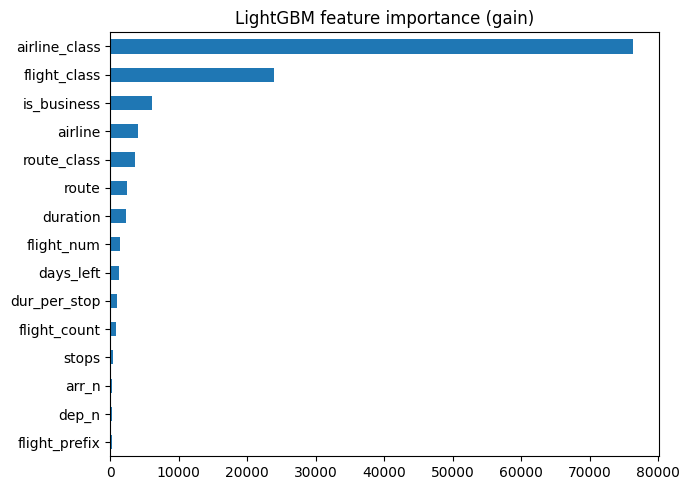

In [32]:
lg = lgb.LGBMRegressor(n_estimators=600, learning_rate=0.05, num_leaves=63, subsample=0.8, subsample_freq=1,
                       colsample_bytree=0.7, random_state=SEED, verbose=-1).fit(Xc, np.log1p(y))
imp = pd.Series(lg.booster_.feature_importance("gain"), index=Xc.columns).sort_values()
imp.tail(15).plot.barh(figsize=(7, 5), title="LightGBM feature importance (gain)"); plt.tight_layout(); plt.show()

**Reading this.** Business fares on premium airlines, one stop, long duration carry almost all of the error, and prices for an identical itinerary can range over 3-4x. What drives that (most likely the actual departure date, which the dataset does not contain) is not recoverable from the available columns, so an R² around 0.93-0.94 is close to what these features allow; chasing a much higher score would mean fitting noise. Ideas tried during development that did **not** help under cross-validation: out-of-fold group-price features, target-encoded neighbour features, dropping high-cardinality categoricals, stronger categorical regularisation, finer histogram bins and Huber loss.

## 12. Submission

In [33]:
sub = pd.DataFrame({"id": test["id"], "price": np.clip(test_final, 3000, None)})
assert len(sub) == len(sample) and sub.id.equals(sample.id) and sub.price.notna().all()
sub.to_csv("submission.csv", index=False)
print(sub.shape); print(sub.price.describe().round(0).to_string())
sub.head()

(3898, 2)
count      3898.0
mean      29748.0
std       38043.0
min        3830.0
25%        7350.0
50%       10026.0
75%       36473.0
max      245746.0


,id,price
0,1,8675.180577
1,2,7370.376225
2,3,27843.167776
3,4,32136.315673
4,5,4559.065123


In [34]:
try:                                  # in Colab this downloads the file to your computer
    from google.colab import files
    files.download("submission.csv")
except ImportError:
    pass

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 13. Conclusion
**Final model:** the average of the six tree models (Random Forest, XGBoost and LightGBM, each in two variants) × 1.01, with the exact-match lookup (weight 0.9) for test rows that have an identical flight in train.

| Step | CV RMSE | CV R² |
|---|---|---|
| Best single model (XGBoost, log target) | 10,127 | 0.9330 |
| Average of 6 tree models × 1.01 | 9,990 | 0.9348 |
| + exact-match lookup (final) | **9,877** | **0.9363** |

**Tree vs linear models.** The best linear model, Ridge with a separate duration slope per airline, reaches R² 0.9207 (RMSE 11,018). The penalty barely mattered: Linear Regression 0.9171, Lasso 0.9172 and Ridge 0.9176. The one hand-built interaction, a duration slope per airline, helped most. Trees win because they learn interactions such as airline × stops × duration × class on their own, while a linear model only sees the interactions it is given.

**Where the remaining error is.** 99% of the squared error comes from Business tickets, and 73% from fares above ₹100k. The same flight on the same route sells for anywhere between about ₹81k and ₹308k (EY 353 in section 11), and nothing in the columns explains the difference. Even the average price of all other rows of the same flight and class scores only R² 0.9193, below the final model. So R² around 0.94 is close to what these features allow.

